In [242]:
import numpy as np 
import pandas as pd 
from tensorflow.keras.models import Sequential
import tensorflow as tf
import matplotlib.pyplot as plt 
from tensorflow.keras.layers import(Conv2D,MaxPooling2D,Flatten,Dense)


In [243]:
from tensorflow.keras.datasets import mnist

(X_train ,y_train),(X_test ,y_test)=mnist.load_data()

In [244]:
X_train.shape

(60000, 28, 28)

In [245]:
y_train.shape

(60000,)

In [246]:
X_test.shape

(10000, 28, 28)

In [247]:
y_test.shape

(10000,)

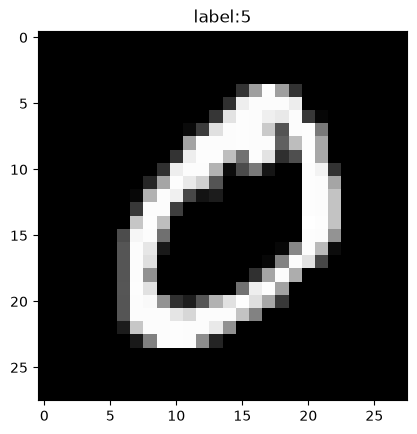

In [248]:
plt.imshow(
    X_train[1],
    cmap='gray'
)
plt.title(f"label:{y_train[0]}")
plt.show()

In [249]:
X_train = X_train.reshape(-1, 28, 28, 1)/ 255
X_test = X_test.reshape(-1, 28, 28, 1) / 255

In [250]:
X_train=X_train.reshape(
    -1,28,28,1
)

In [251]:
X_test = X_test.reshape(
    -1,28, 28 ,1)

In [252]:
model=Sequential()

In [253]:
model.add(
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(28,28,1)
    )
)

c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [254]:
model.add(
    MaxPooling2D(
        pool_size=(2,2)
    )
)

In [255]:
model.add(
    Conv2D(
        filters=64,
        kernel_size=(3,3),
        activation="relu"
    )
)

In [256]:
model.add(
    MaxPooling2D(
        pool_size=(2, 2)
    )
)

In [257]:
model.add(
    Flatten()
)

In [258]:
model.add(
    Dense(
        128,
        activation="relu"
    )
)

In [259]:
model.add(
    Dense(
        10,
        activation="softmax"
    )
)

In [260]:
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [261]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [263]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_test,y_test)
)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 31s 33ms/step - accuracy: 0.9860 - loss: 0.0468 - val_accuracy: 0.9871 - val_loss: 0.0384
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 30s 32ms/step - accuracy: 0.9900 - loss: 0.0316 - val_accuracy: 0.9883 - val_loss: 0.0372
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 40s 31ms/step - accuracy: 0.9930 - loss: 0.0226 - val_accuracy: 0.9900 - val_loss: 0.0308
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 31ms/step - accuracy: 0.9944 - loss: 0.0171 - val_accuracy: 0.9891 - val_loss: 0.0333
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 44s 34ms/step - accuracy: 0.9955 - loss: 0.0141 - val_accuracy: 0.9908 - val_loss: 0.0323


In [278]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9908 - loss: 0.0323


In [277]:
print(
    "Test Accuracy:",
    test_accuracy
)

Test Accuracy: 0.09799999743700027


In [273]:
prediction = model.predict(
    X_test[0:1]
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step


In [274]:
predicted_class = prediction.argmax()


In [275]:
print(
    "Predicted:",
    predicted_class
)

Predicted: 7


In [276]:
print(
    "Actual:",
    y_test[0]
)

Actual: 7
